In [4]:
import rasterio 
from pathlib import Path
import matplotlib.pyplot as plt 

# ====================================
# DATA DIRECTORY PATH 
# ====================================

# --------------------------
# Project root directory 
# --------------------------

# lola_root = Path(__file__).resolve().parent.parent                              # Usage for Spyder  
lola_root = Path.cwd().parent                                                   # Usage for Jupyterlab

# --------------------------
# Data directory & folder 
# --------------------------

data_path = lola_root / 'data' / 'gdr_cylindrical'
data_path.mkdir(parents=True, exist_ok=True)

# ==============================================================
# Step 1. Scan Directory and Build Data Dictionary 
# ==============================================================

print('Select product type to filter: ')
print('1. LDEM (Topographic elevation models)')
print('2. LDEC (Observation count maps)')
print('3. LDAC (Albedo/data count maps)')
print('4. All products')

choice = input('Enter choice (1-4): ').strip()

prefix_map = {
    '1':'ldem',
    '2':'ldec',
    '3':'ldac',
    '4': ''
}

selected_prefix = prefix_map.get(choice, '')
search_pattern = f"{selected_prefix}*.lbl"

lbl_files = sorted(list(data_path.glob(search_pattern)))

if not lbl_files:
    print('No .lbl files found in the data directory')
    data_dict = {}
else: 
    # build dictionary mapping index/name to file path 
    data_dict = {i: path for i, path in enumerate(lbl_files)}
    
    print(f'\nFound {len(lbl_files)} files. Available items in dictionary:')
    for idx, path in list(data_dict.items())[:10]: # Show the first 10 for preview 
        print(f'[{idx}] {path.name}')
    if len(data_dict) > 10:
        print(f'... and  {len(lbl_files) - 10} more.')

Select product type to filter: 
1. LDEM (Topographic elevation models)
2. LDEC (Observation count maps)
3. LDAC (Albedo/data count maps)
4. All products


Enter choice (1-4):  1



Found 168 files. Available items in dictionary:
[0] ldem_1024_00n_15n_000_030.lbl
[1] ldem_1024_00n_15n_030_060.lbl
[2] ldem_1024_00n_15n_060_090.lbl
[3] ldem_1024_00n_15n_090_120.lbl
[4] ldem_1024_00n_15n_120_150.lbl
[5] ldem_1024_00n_15n_150_180.lbl
[6] ldem_1024_00n_15n_180_210.lbl
[7] ldem_1024_00n_15n_210_240.lbl
[8] ldem_1024_00n_15n_240_270.lbl
[9] ldem_1024_00n_15n_270_300.lbl
... and  158 more.



Enter the dictionary index of the file you want to plot:  0


Loading and downsampling (factor: 4): ldem_1024_00n_15n_000_030.lbl


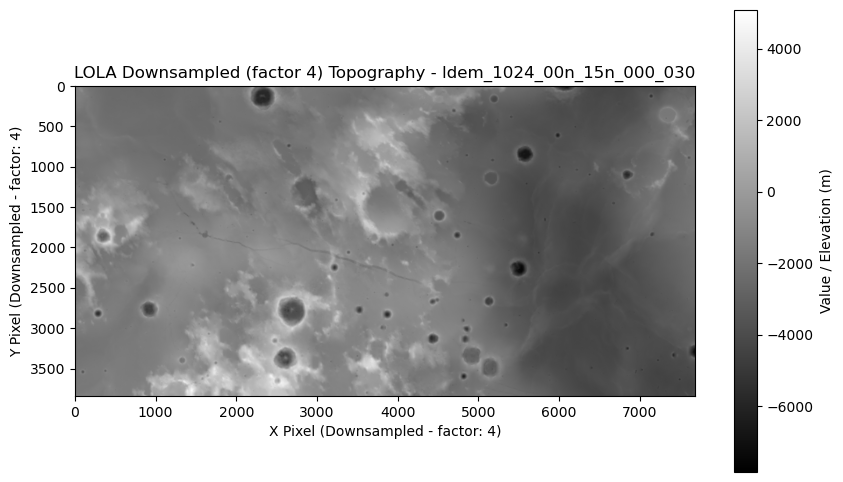

In [8]:
# ====================================
# DOWNSCALE FACTOR  
# ====================================

DOWNSCALE_FACTOR = 4

# ==============================================================
# Step 2. Select, Downsample, and Plot 
# ==============================================================

if 'data_dict' in locals() and data_dict:
    selected_idx = int(input('\nEnter the dictionary index of the file you want to plot: '))

    if selected_idx in data_dict:
        lbl_path = data_dict[selected_idx]
        print(f'Loading and downsampling (factor: {DOWNSCALE_FACTOR}): {lbl_path.name}')

        with rasterio.open(lbl_path) as src: 
            scale_factor = DOWNSCALE_FACTOR
            h_out = max(1, src.height // scale_factor)
            w_out = max(1, src.width // scale_factor)

            elevation = src.read(
                1,
                out_shape=(h_out, w_out),
                resampling=rasterio.enums.Resampling.average
            )

        plt.figure(figsize=(10,6))
        plt.imshow(elevation, cmap='gray', origin='upper')
        plt.colorbar(label='Value / Elevation (m)')
        plt.title(f'LOLA Downsampled (factor {DOWNSCALE_FACTOR}) Topography - {lbl_path.stem}')
        plt.xlabel(f'X Pixel (Downsampled - factor: {DOWNSCALE_FACTOR})')
        plt.ylabel(f'Y Pixel (Downsampled - factor: {DOWNSCALE_FACTOR})') 
        plt.show()